# Bulls' Ticket & Membership Sales Analysis

Analyze Bulls home attendance by season, opponent, day of week, and team performance. Translate the findings into practical ticket and partial-season membership ideas.

## 1. Setup

In [1]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup, Comment
from scipy import stats
from IPython.display import display

sns.set_theme(style = "whitegrid", palette = "deep")
pd.set_option("display.max_columns", 30)
SEASON_END_YEARS = [2023, 2024, 2025, 2026]
ASSUMED_CAPACITY = 20917

## 2. Download Bulls home-game attendance

In [2]:
REQUIRED = {"date", "season", "opponent", "attendance", "bulls_points", "opponent_points", "result"}

def cell_text(row, key):
    tag = row.find(["td", "th"], attrs = {"data-stat": key})
    return tag.get_text(" ", strip = True) if tag else ""

def find_games_table(html):
    soup = BeautifulSoup(html, "html.parser")
    table = soup.find("table", id = "games")
    if table is not None: return table
    for comment in soup.find_all(string = lambda value: isinstance(value, Comment)):
        if "id=\"games\"" in str(comment):
            table = BeautifulSoup(str(comment), "html.parser").find("table", id = "games")
            if table is not None: return table
    raise ValueError("Games table not found")

def fetch_bulls_season(year, session):
    url = f"https://www.basketball-reference.com/teams/CHI/{year}_games.html"
    response = session.get(url, timeout = 30)
    response.raise_for_status()
    table = find_games_table(response.text)
    records = []
    for row in table.select("tbody tr"):
        if "thead" in row.get("class", []): continue
        date = cell_text(row, "date_game")
        opponent = cell_text(row, "opp_name")
        attendance = cell_text(row, "attendance")
        if not date or not opponent or cell_text(row, "game_location") == "@" or not re.search(r"\d", attendance): continue
        records.append({"date": date, "season": f"{year - 1}-{str(year)[-2:]}", "opponent": opponent, "attendance": attendance, "bulls_points": cell_text(row, "pts"), "opponent_points": cell_text(row, "opp_pts"), "result": cell_text(row, "game_result"), "wins_after": cell_text(row, "wins"), "losses_after": cell_text(row, "losses"), "source_url": url})
    if not records: raise ValueError("No home attendance records found")
    return pd.DataFrame(records)

def load_bulls_data():
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0", "Accept-Language": "en-US,en;q=0.9"})
    frames = []
    for year in SEASON_END_YEARS:
        try:
            frame = fetch_bulls_season(year, session)
            frames.append(frame)
            print(f"{year - 1}-{str(year)[-2:]}: {len(frame)} home games loaded")
        except Exception as exc:
            print(f"{year - 1}-{str(year)[-2:]}: skipped ({exc})")
        time.sleep(2)
    if not frames: raise RuntimeError("No seasons could be downloaded; check internet access or source availability")
    return pd.concat(frames, ignore_index = True)

raw = load_bulls_data()
missing = REQUIRED - set(raw.columns)
if missing: raise ValueError(f"Missing columns: {sorted(missing)}")
display(raw.head())

2022-23: 41 home games loaded
2023-24: 42 home games loaded
2024-25: 42 home games loaded
2025-26: 41 home games loaded


,date,season,opponent,attendance,bulls_points,opponent_points,result,wins_after,losses_after,source_url
0,"Sat, Oct 22, 2022",2022-23,Cleveland Cavaliers,"21,089",96,128,L,1,2,https://www.basketball-reference.com/teams/CHI...
1,"Mon, Oct 24, 2022",2022-23,Boston Celtics,"17,673",120,102,W,2,2,https://www.basketball-reference.com/teams/CHI...
2,"Wed, Oct 26, 2022",2022-23,Indiana Pacers,"18,306",124,109,W,3,2,https://www.basketball-reference.com/teams/CHI...
3,"Sat, Oct 29, 2022",2022-23,Philadelphia 76ers,"19,010",109,114,L,3,4,https://www.basketball-reference.com/teams/CHI...
4,"Wed, Nov 2, 2022",2022-23,Charlotte Hornets,"17,886",106,88,W,5,4,https://www.basketball-reference.com/teams/CHI...


## 3. Clean the data

In [3]:
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors = "coerce")
for column in ["attendance", "bulls_points", "opponent_points", "wins_after", "losses_after"]:
    df[column] = pd.to_numeric(df[column].astype(str).str.replace(",", "", regex = False), errors = "coerce")
df["season"] = df["season"].astype(str).str.strip()
df["opponent"] = df["opponent"].astype(str).str.strip()
df["result"] = df["result"].astype(str).str.upper().str.strip().str[:1]
df = df.dropna(subset = ["date", "attendance", "opponent", "season"]).copy()
df = df.loc[df["attendance"] > 0].drop_duplicates(subset = ["date", "season", "opponent"]).sort_values("date").reset_index(drop = True)
if df.empty: raise ValueError("No valid games remain after cleaning")
if not df["attendance"].between(1, 30000).all(): raise ValueError("Unexpected attendance value; inspect downloaded rows")
df["day_of_week"] = df["date"].dt.day_name()
df["month_number"] = df["date"].dt.month
df["weekend"] = df["date"].dt.dayofweek.isin([4, 5, 6])
df["capacity_pct"] = 100 * df["attendance"] / ASSUMED_CAPACITY
before_wins = df["wins_after"] - df["result"].eq("W").astype(int)
before_losses = df["losses_after"] - df["result"].eq("L").astype(int)
prior_games = before_wins + before_losses
valid_record = df["result"].isin(["W", "L"]) & prior_games.gt(0) & df["wins_after"].notna() & df["losses_after"].notna()
df["pregame_win_pct"] = (before_wins / prior_games).where(valid_record)
print(f"Games analyzed: {len(df)} | Seasons: {df["season"].nunique()}")
display(df.groupby("season", as_index = False).agg(games = ("attendance", "size"), average_attendance = ("attendance", "mean"), total_attendance = ("attendance", "sum")).round(1))

Games analyzed: 166 | Seasons: 4


,season,games,average_attendance,total_attendance
0,2022-23,41,20527.6,841632
1,2023-24,42,20648.7,867247
2,2024-25,42,20167.6,847039
3,2025-26,41,20243.8,829997


## 4. Attendance overview

,Value
Home games,166.0
Seasons,4.0
Average attendance,20397.0
Median attendance,20758.0
Standard deviation,1167.0
Minimum attendance,17210.0
Maximum attendance,22491.0
Average capacity percentage,97.5


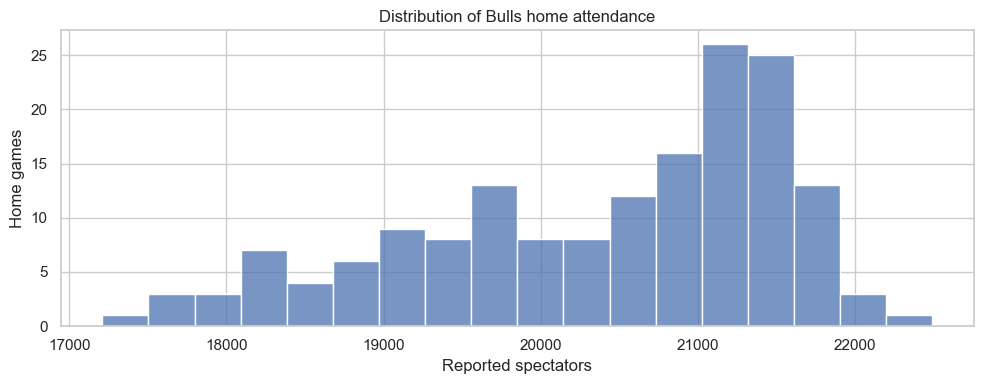

In [4]:
overview = pd.Series({"Home games": len(df), "Seasons": df["season"].nunique(), "Average attendance": round(df["attendance"].mean()), "Median attendance": round(df["attendance"].median()), "Standard deviation": round(df["attendance"].std()), "Minimum attendance": int(df["attendance"].min()), "Maximum attendance": int(df["attendance"].max()), "Average capacity percentage": round(df["capacity_pct"].mean(), 1)})
display(overview.to_frame("Value"))
fig, ax = plt.subplots(figsize = (10, 4))
sns.histplot(data = df, x = "attendance", bins = 18, ax = ax)
ax.set(title = "Distribution of Bulls home attendance", xlabel = "Reported spectators", ylabel = "Home games")
plt.tight_layout()
plt.show()

## 5. Attendance across seasons

,season,games,average,median,total
0,2022-23,41,20527.6,20944.0,841632
1,2023-24,42,20648.7,21151.0,867247
2,2024-25,42,20167.6,20254.5,847039
3,2025-26,41,20243.8,20633.0,829997


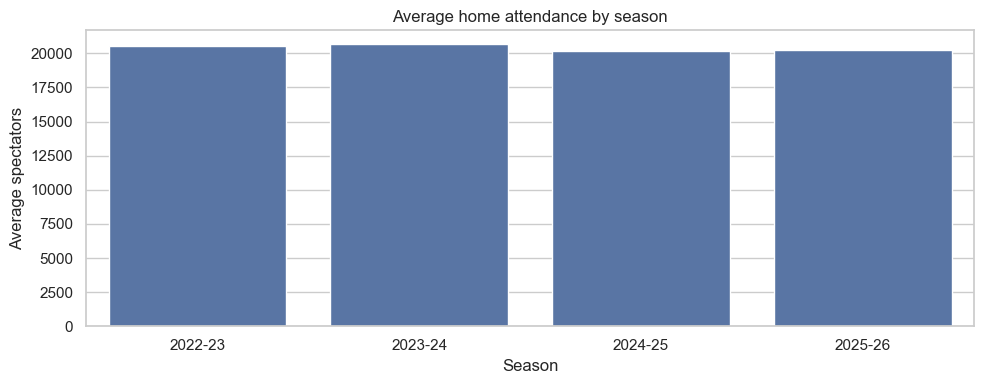

In [5]:
season_stats = df.groupby("season", as_index = False).agg(games = ("attendance", "size"), average = ("attendance", "mean"), median = ("attendance", "median"), total = ("attendance", "sum")).sort_values("season")
display(season_stats.round(1))
fig, ax = plt.subplots(figsize = (10, 4))
sns.barplot(data = season_stats, x = "season", y = "average", ax = ax)
ax.set(title = "Average home attendance by season", xlabel = "Season", ylabel = "Average spectators")
plt.tight_layout()
plt.show()

## 6. Which opponents attract the biggest crowds?

,opponent,games,average,total
12,Los Angeles Lakers,4,21557.0,86228
9,Houston Rockets,4,21193.0,84772
28,Washington Wizards,7,21126.7,147887
15,Milwaukee Bucks,8,20920.0,167360
6,Denver Nuggets,4,20744.2,82977
2,Brooklyn Nets,7,20644.7,144513
10,Indiana Pacers,8,20642.6,165141
19,Oklahoma City Thunder,4,20548.8,82195
16,Minnesota Timberwolves,4,20527.0,82108
4,Cleveland Cavaliers,8,20504.2,164034


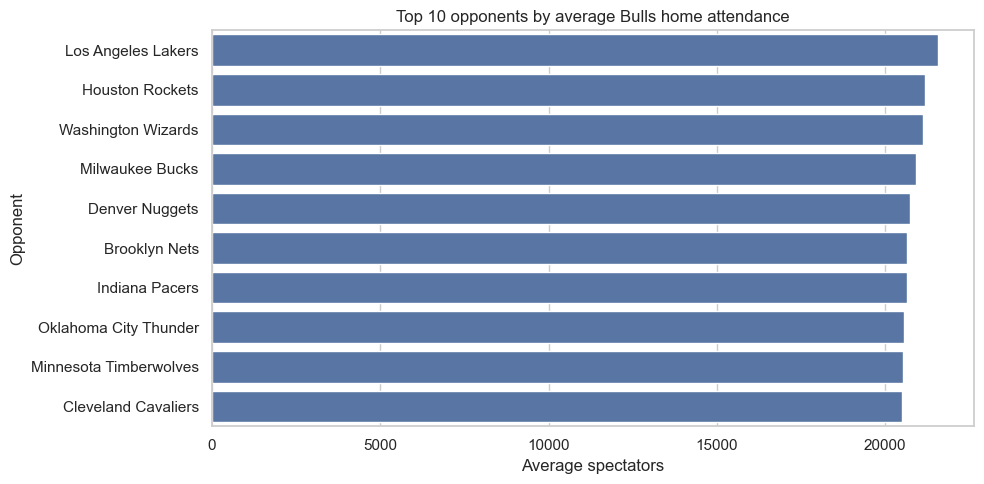

In [6]:
opponent_stats = df.groupby("opponent", as_index = False).agg(games = ("attendance", "size"), average = ("attendance", "mean"), total = ("attendance", "sum")).sort_values("average", ascending = False)
display(opponent_stats.round(1))
repeat_opponents = opponent_stats.loc[opponent_stats["games"] >= 2]
top_opponents = repeat_opponents.head(10)
fig, ax = plt.subplots(figsize = (10, 5))
sns.barplot(data = top_opponents, y = "opponent", x = "average", ax = ax)
ax.set(title = "Top 10 opponents by average Bulls home attendance", xlabel = "Average spectators", ylabel = "Opponent")
plt.tight_layout()
plt.show()

## 7. Weekday versus weekend attendance

,day_of_week,games,average
1,Monday,26,20299.2
5,Tuesday,17,20120.6
6,Wednesday,33,20093.1
4,Thursday,14,20471.5
0,Friday,29,20711.8
2,Saturday,31,20790.5
3,Sunday,16,20078.9


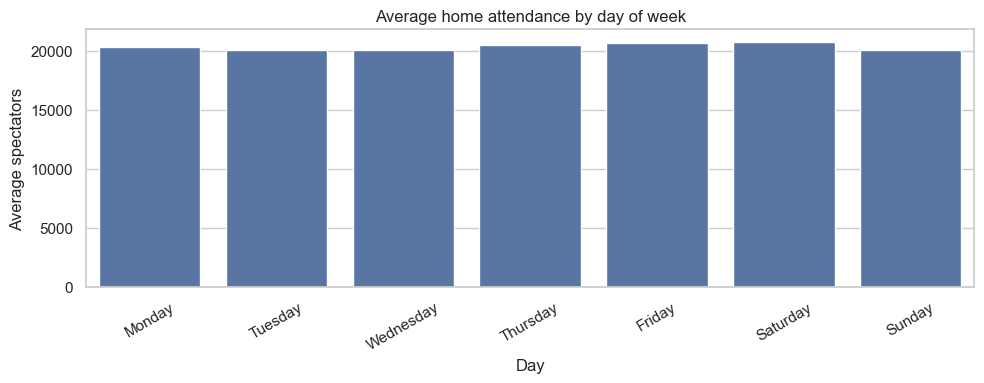

Friday–Sunday average: 20,611 | Monday–Thursday average: 20,217
Difference: +394 | Welch t-test p-value: 0.0269


In [7]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_stats = df.groupby("day_of_week", as_index = False).agg(games = ("attendance", "size"), average = ("attendance", "mean"))
day_stats["day_of_week"] = pd.Categorical(day_stats["day_of_week"], categories = day_order, ordered = True)
day_stats = day_stats.sort_values("day_of_week")
display(day_stats.round(1))
fig, ax = plt.subplots(figsize = (10, 4))
sns.barplot(data = day_stats, x = "day_of_week", y = "average", ax = ax)
ax.set(title = "Average home attendance by day of week", xlabel = "Day", ylabel = "Average spectators")
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()
weekend = df.loc[df["weekend"], "attendance"].to_numpy(dtype = float)
weekday = df.loc[~df["weekend"], "attendance"].to_numpy(dtype = float)
if len(weekend) >= 2 and len(weekday) >= 2:
    test = stats.ttest_ind(weekend, weekday, equal_var = False)
    print(f"Friday–Sunday average: {weekend.mean():,.0f} | Monday–Thursday average: {weekday.mean():,.0f}")
    print(f"Difference: {weekend.mean() - weekday.mean():+,.0f} | Welch t-test p-value: {test.pvalue:.4f}")

## 8. Monthly and calendar patterns

,month_number,games,average
4,10,12,19480.2
5,11,26,19982.2
6,12,33,20270.6
0,1,29,20406.8
1,2,25,20365.7
2,3,26,20920.3
3,4,15,21254.7


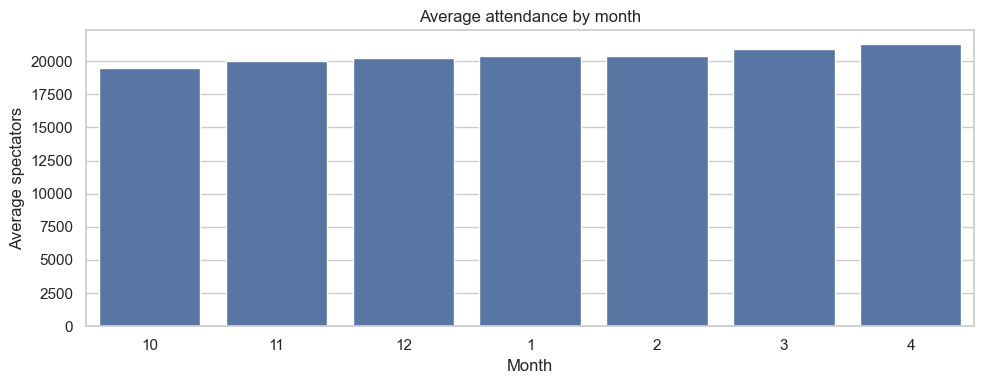

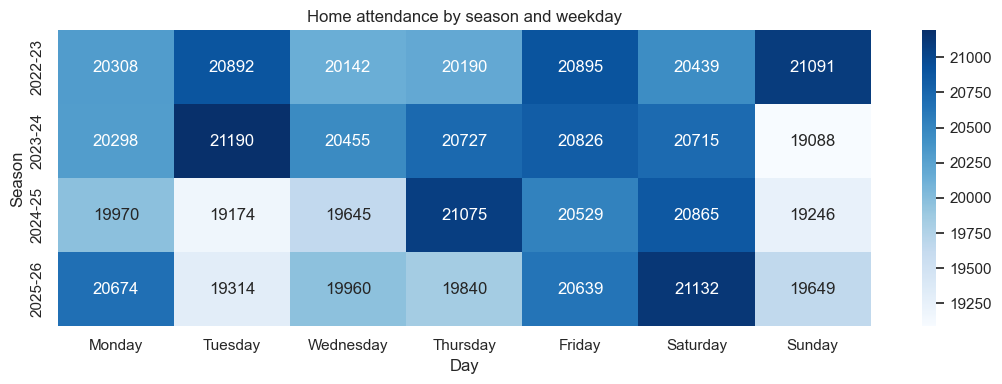

In [8]:
month_order = [10, 11, 12, 1, 2, 3, 4]
monthly = df.groupby("month_number", as_index = False).agg(games = ("attendance", "size"), average = ("attendance", "mean"))
monthly["month_number"] = pd.Categorical(monthly["month_number"], categories = month_order, ordered = True)
monthly = monthly.sort_values("month_number")
display(monthly.round(1))
fig, ax = plt.subplots(figsize = (10, 4))
sns.barplot(data = monthly, x = "month_number", y = "average", ax = ax)
ax.set(title = "Average attendance by month", xlabel = "Month", ylabel = "Average spectators")
plt.tight_layout()
plt.show()
season_day = df.pivot_table(index = "season", columns = "day_of_week", values = "attendance", aggfunc = "mean").reindex(columns = day_order)
fig, ax = plt.subplots(figsize = (11, 4))
sns.heatmap(season_day, annot = True, fmt = ".0f", cmap = "Blues", ax = ax)
ax.set(title = "Home attendance by season and weekday", xlabel = "Day", ylabel = "Season")
plt.tight_layout()
plt.show()

## 9. Team performance and attendance

Pearson correlation: +0.036 (p = 0.6441)
Spearman correlation: +0.282 (p = 0.0002)


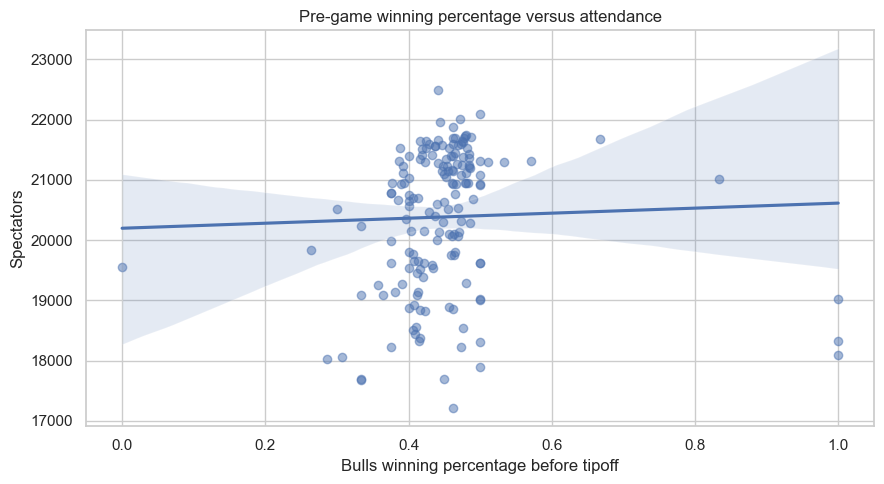

In [9]:
performance = df.dropna(subset = ["pregame_win_pct", "attendance"])
if len(performance) >= 8 and performance["pregame_win_pct"].nunique() > 1:
    pearson = stats.pearsonr(performance["pregame_win_pct"], performance["attendance"])
    spearman = stats.spearmanr(performance["pregame_win_pct"], performance["attendance"])
    print(f"Pearson correlation: {pearson.statistic:+.3f} (p = {pearson.pvalue:.4f})")
    print(f"Spearman correlation: {spearman.statistic:+.3f} (p = {spearman.pvalue:.4f})")
    fig, ax = plt.subplots(figsize = (9, 5))
    sns.regplot(data = performance, x = "pregame_win_pct", y = "attendance", scatter_kws = {"alpha": 0.5}, ax = ax)
    ax.set(title = "Pre-game winning percentage versus attendance", xlabel = "Bulls winning percentage before tipoff", ylabel = "Spectators")
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient pre-game record data for this comparison")

## 10. Statistical comparison of opponents

In [10]:
groups = [group["attendance"].to_numpy() for _, group in df.groupby("opponent") if len(group) >= 3]
if len(groups) >= 3:
    test = stats.kruskal(*groups)
    print(f"Kruskal–Wallis statistic: {test.statistic:.2f} | p-value: {test.pvalue:.4f} | Opponent groups: {len(groups)}")
else:
    print("Not enough repeated opponent matchups for the Kruskal–Wallis test")

Kruskal–Wallis statistic: 23.40 | p-value: 0.7128 | Opponent groups: 29


## 11. Find lower-attendance games

,date,season,opponent,day_of_week,attendance
1,2022-10-24,2022-23,Boston Celtics,Monday,17673
4,2022-11-02,2022-23,Charlotte Hornets,Wednesday,17886
2,2022-10-26,2022-23,Indiana Pacers,Wednesday,18306
12,2022-12-14,2022-23,New York Knicks,Wednesday,18820
3,2022-10-29,2022-23,Philadelphia 76ers,Saturday,19010
10,2022-12-07,2022-23,Washington Wizards,Wednesday,19265
26,2023-02-06,2022-23,San Antonio Spurs,Monday,19291
11,2022-12-10,2022-23,Dallas Mavericks,Saturday,19528
6,2022-11-09,2022-23,New Orleans Pelicans,Wednesday,19621
13,2022-12-16,2022-23,New York Knicks,Friday,19661


,games,low_share
day_of_week,,
Monday,26,26.9
Tuesday,17,35.3
Wednesday,33,45.5
Thursday,14,14.3
Friday,29,13.8
Saturday,31,16.1
Sunday,16,31.2


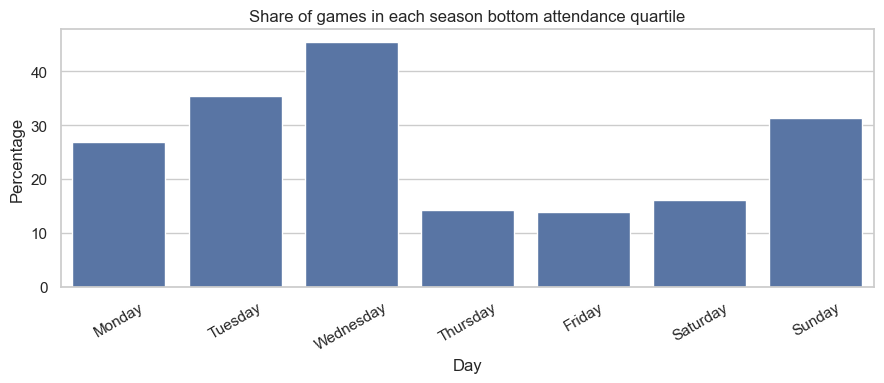

In [11]:
df["season_q25"] = df.groupby("season")["attendance"].transform(lambda values: values.quantile(0.25))
df["low_attendance"] = df["attendance"] <= df["season_q25"]
low_games = df.loc[df["low_attendance"], ["date", "season", "opponent", "day_of_week", "attendance"]].sort_values(["season", "attendance"])
display(low_games.head(25))
low_by_day = df.groupby("day_of_week").agg(games = ("attendance", "size"), low_share = ("low_attendance", "mean")).reindex(day_order)
low_by_day["low_share"] = 100 * low_by_day["low_share"]
display(low_by_day.round(1))
fig, ax = plt.subplots(figsize = (9, 4))
sns.barplot(x = low_by_day.index, y = low_by_day["low_share"], ax = ax)
ax.set(title = "Share of games in each season bottom attendance quartile", xlabel = "Day", ylabel = "Percentage")
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

## 12. Ticket and membership opportunities

In [12]:
top_names = ", ".join(repeat_opponents.head(5)["opponent"].tolist())
low_names = ", ".join(repeat_opponents.tail(5)["opponent"].tolist())
recommendations = pd.DataFrame([{"Finding": "Higher-attendance opponents", "Examples": top_names, "Sales idea": "Feature popular matchups in partial-season packages"}, {"Finding": "Lower-attendance opponents", "Examples": low_names, "Sales idea": "Bundle lower-demand dates with higher-demand games"}, {"Finding": "Weekend versus weekday demand", "Examples": f"Weekend: {weekend.mean():,.0f}; weekday: {weekday.mean():,.0f}" if len(weekend) and len(weekday) else "Unavailable", "Sales idea": "Test separate weekday and weekend membership packages"}, {"Finding": "Historically low-attendance dates", "Examples": f"{len(low_games)} flagged games", "Sales idea": "Prioritize targeted promotions and group-ticket outreach"}])
display(recommendations)

,Finding,Examples,Sales idea
0,Higher-attendance opponents,"Los Angeles Lakers, Houston Rockets, Washingto...",Feature popular matchups in partial-season pac...
1,Lower-attendance opponents,"Miami Heat, Los Angeles Clippers, Charlotte Ho...",Bundle lower-demand dates with higher-demand g...
2,Weekend versus weekday demand,"Weekend: 20,611; weekday: 20,217",Test separate weekday and weekend membership p...
3,Historically low-attendance dates,44 flagged games,Prioritize targeted promotions and group-ticke...


## 13. Final business summary

In [13]:
best_season = season_stats.loc[season_stats["average"].idxmax()]
best_opponent = repeat_opponents.iloc[0]["opponent"] if not repeat_opponents.empty else "Unavailable"
print("CHICAGO BULLS | TICKET SALES & MEMBERSHIP ANALYSIS")
print(f"Seasons: {", ".join(sorted(df["season"].unique()))}")
print(f"Home games analyzed: {len(df)}")
print(f"Average attendance: {df["attendance"].mean():,.0f}")
print(f"Highest average-attendance season: {best_season["season"]}")
print(f"Highest average-attendance recurring opponent: {best_opponent}")
print("\nRECOMMENDATIONS")
print("1. Build partial-season packages featuring high-demand opponents alongside lower-demand dates.")
print("2. Use weekday attendance patterns to inform package mix and marketing priorities.")
print("3. Target historically lower-attendance matchups with testable group-sales promotions.")
print("4. Validate ideas using actual ticket purchases, membership conversions, and sales revenue.")

CHICAGO BULLS | TICKET SALES & MEMBERSHIP ANALYSIS
Seasons: 2022-23, 2023-24, 2024-25, 2025-26
Home games analyzed: 166
Average attendance: 20,397
Highest average-attendance season: 2023-24
Highest average-attendance recurring opponent: Los Angeles Lakers

RECOMMENDATIONS
1. Build partial-season packages featuring high-demand opponents alongside lower-demand dates.
2. Use weekday attendance patterns to inform package mix and marketing priorities.
3. Target historically lower-attendance matchups with testable group-sales promotions.
4. Validate ideas using actual ticket purchases, membership conversions, and sales revenue.
